In [3]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

import nltk

warnings.filterwarnings("ignore")

# Create output folder
os.makedirs("visualizations", exist_ok=True)
os.makedirs("data", exist_ok=True)

# Download required NLTK resources
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("vader_lexicon")

# Set visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\balam\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\balam\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\balam\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\balam\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\balam\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\balam\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_d

Libraries imported successfully.


In [ ]:
DATA_PATH = "data\reviews_raw.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Place your CSV file inside the data folder and name it reviews_raw.csv."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (568454, 10)


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [5]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 43.4 MB

Missing values:


Summary                   27
ProfileName               26
ProductId                  0
Id                         0
HelpfulnessNumerator       0
UserId                     0
HelpfulnessDenominator     0
Score                      0
Time                       0
Text                       0
dtype: int64


Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,568454.0,NaN,NaN,NaN,284227.5,164098.679298,1.0,142114.25,284227.5,426340.75,568454.0
ProductId,568454,74258,B007JFMH8M,913,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UserId,568454,256059,A3OXHLG6DIBRW8,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ProfileName,568428,218415,"C. F. Hill ""CFH""",451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HelpfulnessNumerator,568454.0,NaN,NaN,NaN,1.743817,7.636513,0.0,0.0,0.0,2.0,866.0
HelpfulnessDenominator,568454.0,NaN,NaN,NaN,2.22881,8.28974,0.0,0.0,1.0,2.0,923.0
Score,568454.0,NaN,NaN,NaN,4.183199,1.310436,1.0,4.0,5.0,5.0,5.0
Time,568454.0,NaN,NaN,NaN,1296256604.90242,48043312.332416,939340800.0,1271289600.0,1311120000.0,1332720000.0,1351209600.0
Summary,568427,295742,Delicious!,2462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Text,568454,393579,"This review will make me sound really stupid, ...",199,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Normalize column names for easier matching
column_lookup = {
    str(col).strip().lower(): col
    for col in df.columns
}

possible_text_columns = [
    "text",
    "review",
    "review_text",
    "content",
    "comment"
]

possible_rating_columns = [
    "score",
    "rating",
    "ratings",
    "stars",
    "overall"
]

possible_summary_columns = [
    "summary",
    "review_title",
    "title"
]

TEXT_COLUMN = next(
    (column_lookup[col] for col in possible_text_columns
     if col in column_lookup),
    None
)

RATING_COLUMN = next(
    (column_lookup[col] for col in possible_rating_columns
     if col in column_lookup),
    None
)

SUMMARY_COLUMN = next(
    (column_lookup[col] for col in possible_summary_columns
     if col in column_lookup),
    None
)

if TEXT_COLUMN is None:
    raise ValueError(
        "Could not automatically identify the review text column. "
        "Check df.columns and set TEXT_COLUMN manually."
    )

print("Review text column:", TEXT_COLUMN)
print("Rating column:", RATING_COLUMN)
print("Summary column:", SUMMARY_COLUMN)

Review text column: Text
Rating column: Score
Summary column: Summary


In [7]:
original_rows = len(df)

# Remove rows with missing review text
df = df.dropna(subset=[TEXT_COLUMN]).copy()

# Convert review text to string
df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str)

# Remove empty reviews
df[TEXT_COLUMN] = df[TEXT_COLUMN].str.strip()
df = df[df[TEXT_COLUMN] != ""]

# Remove duplicate reviews
df = df.drop_duplicates(subset=[TEXT_COLUMN])

# Reset index
df = df.reset_index(drop=True)

print("Original rows:", original_rows)
print("Rows after cleaning:", len(df))
print("Rows removed:", original_rows - len(df))

display(df.head())

Original rows: 568454
Rows after cleaning: 393579
Rows removed: 174875


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [8]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

# Keep sentiment-related words such as "not", "no", and "never"
sentiment_words = {"no", "not", "nor", "never"}

stop_words = stop_words - sentiment_words


def clean_text(text):
    """
    Clean review text:
    - Convert to lowercase
    - Remove URLs and HTML tags
    - Remove unwanted characters
    - Tokenize
    - Remove stopwords
    - Lemmatize
    """
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Keep letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    tokens = word_tokenize(text)

    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(cleaned_tokens)


df["Cleaned_Text"] = df[TEXT_COLUMN].apply(clean_text)

display(df[[TEXT_COLUMN, "Cleaned_Text"]].head())

,Text,Cleaned_Text
0,I have bought several of the Vitality canned d...,bought several vitality canned dog food produc...
1,Product arrived labeled as Jumbo Salted Peanut...,product arrived labeled jumbo salted peanut pe...
2,This is a confection that has been around a fe...,confection around century light pillowy citrus...
3,If you are looking for the secret ingredient i...,looking secret ingredient robitussin believe f...
4,Great taffy at a great price. There was a wid...,great taffy great price wide assortment yummy ...


In [9]:
df["Review_Length"] = df[TEXT_COLUMN].apply(
    lambda text: len(str(text).split())
)

df["Character_Count"] = df[TEXT_COLUMN].apply(
    lambda text: len(str(text))
)

print("Average review length:", round(df["Review_Length"].mean(), 2))
print("Median review length:", df["Review_Length"].median())

display(df[["Review_Length", "Character_Count"]].describe())

Average review length: 79.75
Median review length: 57.0


,Review_Length,Character_Count
count,393579.000000,393579.000000
mean,79.753079,433.829178
std,77.162402,433.002351
min,3.000000,12.000000
25%,34.000000,181.000000
50%,57.000000,304.000000
75%,97.000000,527.000000
max,3432.000000,21409.000000


In [10]:
sia = SentimentIntensityAnalyzer()


def analyze_sentiment(text):
    scores = sia.polarity_scores(str(text))

    compound = scores["compound"]

    if compound >= 0.05:
        sentiment = "Positive"
    elif compound <= -0.05:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    return pd.Series({
        "Negative_Score": scores["neg"],
        "Neutral_Score": scores["neu"],
        "Positive_Score": scores["pos"],
        "Compound_Score": compound,
        "Sentiment": sentiment
    })


sentiment_results = df[TEXT_COLUMN].apply(analyze_sentiment)

df = pd.concat([df, sentiment_results], axis=1)

display(
    df[
        [
            TEXT_COLUMN,
            "Compound_Score",
            "Sentiment"
        ]
    ].head(10)
)

,Text,Compound_Score,Sentiment
0,I have bought several of the Vitality canned d...,0.9441,Positive
1,Product arrived labeled as Jumbo Salted Peanut...,-0.5664,Negative
2,This is a confection that has been around a fe...,0.8265,Positive
3,If you are looking for the secret ingredient i...,0.0000,Neutral
4,Great taffy at a great price. There was a wid...,0.9468,Positive
5,I got a wild hair for taffy and ordered this f...,0.8830,Positive
6,This saltwater taffy had great flavors and was...,0.9346,Positive
7,This taffy is so good. It is very soft and ch...,0.9487,Positive
8,Right now I'm mostly just sprouting this so my...,0.6369,Positive
9,This is a very healthy dog food. Good for thei...,0.8313,Positive


In [11]:

sentiment_counts = df["Sentiment"].value_counts()

sentiment_percentages = (
    df["Sentiment"].value_counts(normalize=True) * 100
).round(2)

sentiment_summary = pd.DataFrame({
    "Count": sentiment_counts,
    "Percentage": sentiment_percentages
})

display(sentiment_summary)

,Count,Percentage
Sentiment,,
Positive,343297,87.22
Negative,41530,10.55
Neutral,8752,2.22


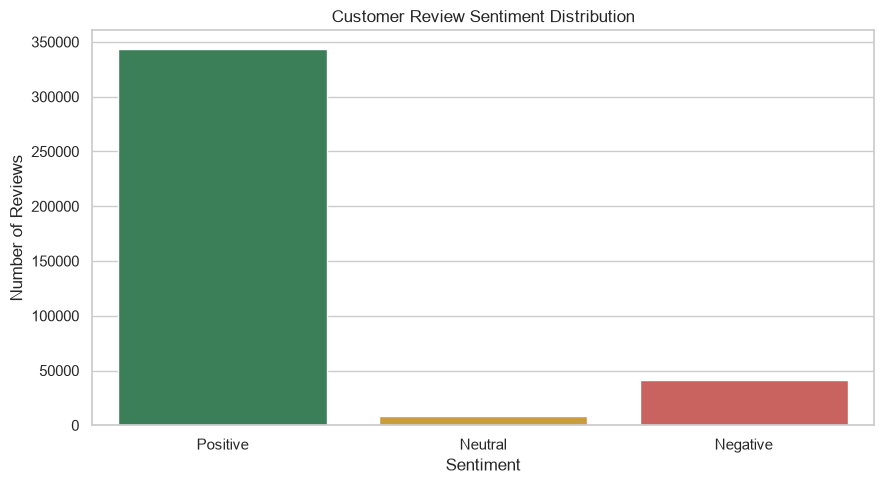

In [12]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Sentiment",
    order=["Positive", "Neutral", "Negative"],
    hue="Sentiment",
    palette={
        "Positive": "#2E8B57",
        "Neutral": "#E0A526",
        "Negative": "#D9534F"
    },
    legend=False
)

plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(
    "visualizations/sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

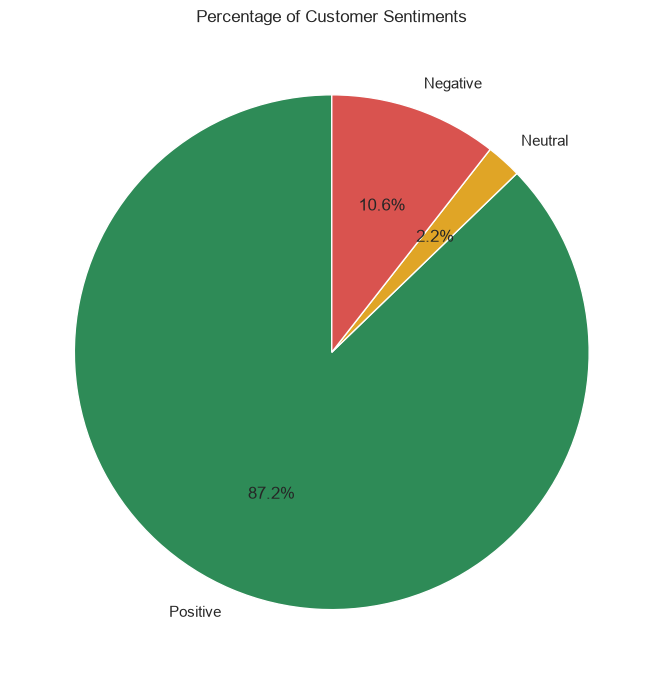

In [13]:
plt.figure(figsize=(7, 7))

colors = ["#2E8B57", "#E0A526", "#D9534F"]

plt.pie(
    sentiment_counts.reindex(
        ["Positive", "Neutral", "Negative"]
    ).fillna(0),
    labels=["Positive", "Neutral", "Negative"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colors
)

plt.title("Percentage of Customer Sentiments")
plt.tight_layout()

plt.savefig(
    "visualizations/sentiment_percentage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Sentiment,Negative,Neutral,Positive
Score,,,
1,45.78,5.48,48.74
2,31.04,4.80,64.16
3,17.76,3.74,78.50
4,6.63,1.83,91.54
5,3.78,1.45,94.78


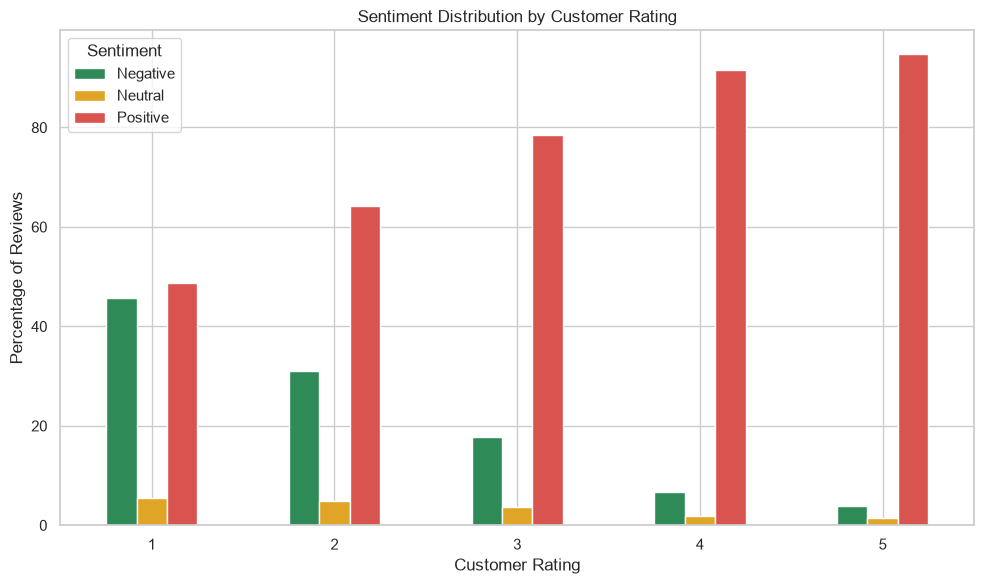

In [14]:
if RATING_COLUMN is not None:

    df[RATING_COLUMN] = pd.to_numeric(
        df[RATING_COLUMN],
        errors="coerce"
    )

    rating_sentiment = pd.crosstab(
        df[RATING_COLUMN],
        df["Sentiment"],
        normalize="index"
    ) * 100

    display(rating_sentiment.round(2))

    rating_sentiment.plot(
        kind="bar",
        figsize=(10, 6),
        color=["#2E8B57", "#E0A526", "#D9534F"]
    )

    plt.title("Sentiment Distribution by Customer Rating")
    plt.xlabel("Customer Rating")
    plt.ylabel("Percentage of Reviews")
    plt.xticks(rotation=0)
    plt.legend(title="Sentiment")
    plt.tight_layout()

    plt.savefig(
        "visualizations/sentiment_by_rating.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("No rating column found. Skipping rating-based analysis.")

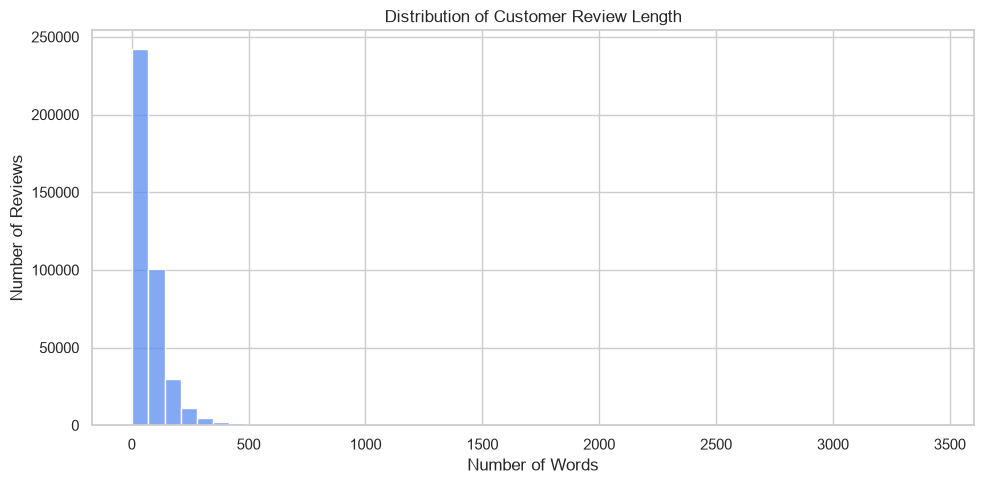

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Review_Length",
    bins=50,
    color="#5B8DEF"
)

plt.title("Distribution of Customer Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(
    "visualizations/review_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

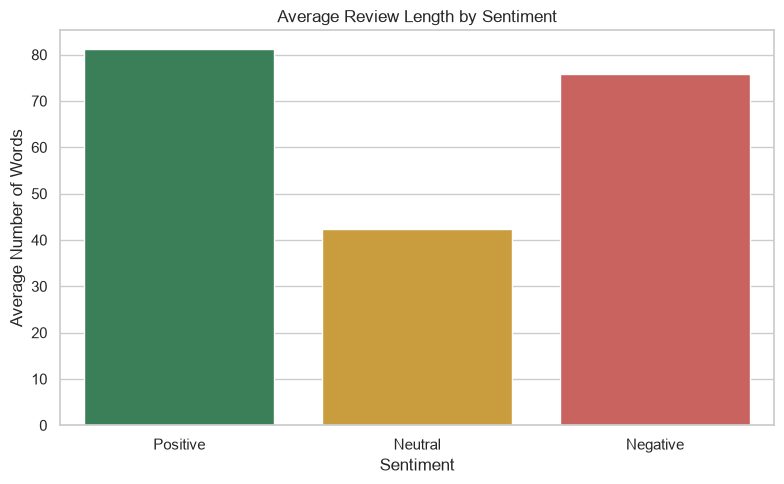

In [16]:
avg_length = (
    df.groupby("Sentiment")["Review_Length"]
    .mean()
    .reindex(["Positive", "Neutral", "Negative"])
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=avg_length.index,
    y=avg_length.values,
    hue=avg_length.index,
    palette={
        "Positive": "#2E8B57",
        "Neutral": "#E0A526",
        "Negative": "#D9534F"
    },
    legend=False
)

plt.title("Average Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")
plt.tight_layout()

plt.savefig(
    "visualizations/average_review_length.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
from collections import Counter

all_words = " ".join(df["Cleaned_Text"].dropna())

word_counts = Counter(all_words.split())

most_common_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

display(most_common_words)

,Word,Frequency
0,not,239051
1,like,180401
2,taste,152898
3,good,140149
4,product,132096
5,one,129520
6,flavor,125177
7,great,114759
8,love,104928
9,coffee,103703


In [18]:
from collections import Counter

all_words = " ".join(df["Cleaned_Text"].dropna())

word_counts = Counter(all_words.split())

most_common_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)

display(most_common_words)

,Word,Frequency
0,not,239051
1,like,180401
2,taste,152898
3,good,140149
4,product,132096
5,one,129520
6,flavor,125177
7,great,114759
8,love,104928
9,coffee,103703


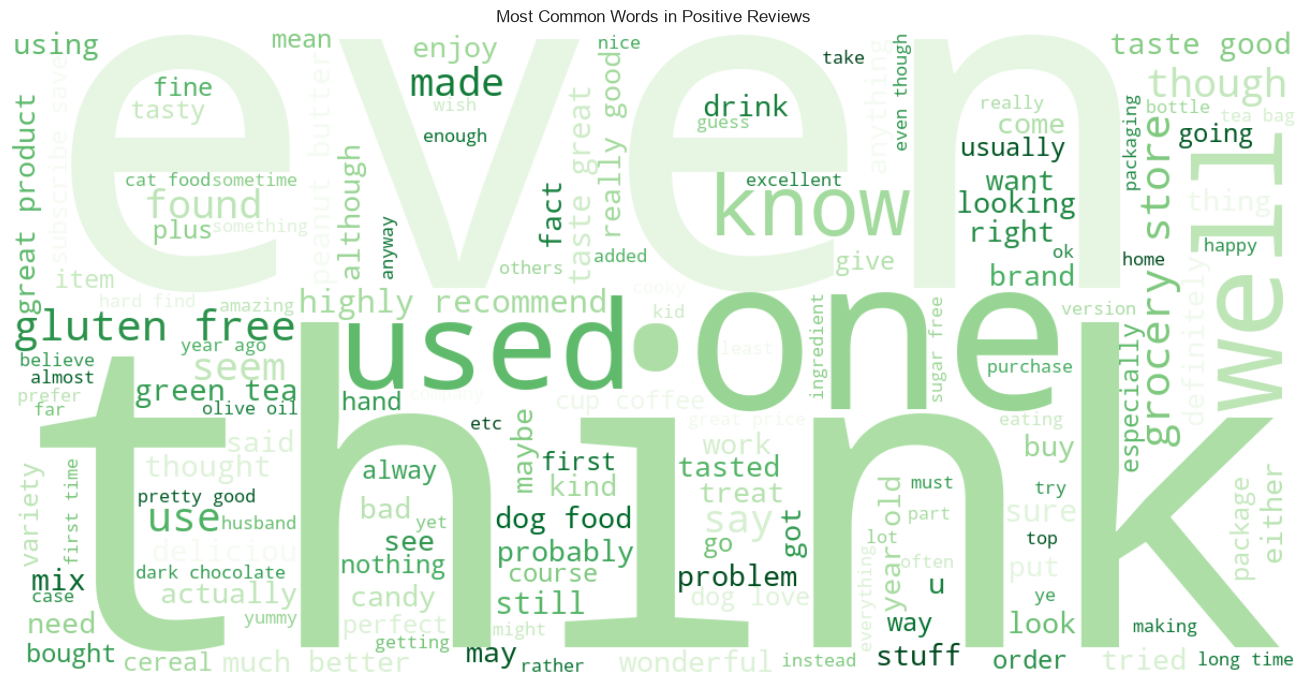

In [19]:
positive_text = " ".join(
    df.loc[df["Sentiment"] == "Positive", "Cleaned_Text"].dropna()
)

if positive_text.strip():

    positive_wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        colormap="Greens",
        max_words=150
    ).generate(positive_text)

    plt.figure(figsize=(14, 7))
    plt.imshow(positive_wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Most Common Words in Positive Reviews")
    plt.tight_layout()

    plt.savefig(
        "visualizations/positive_wordcloud.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("No positive reviews available for word cloud.")

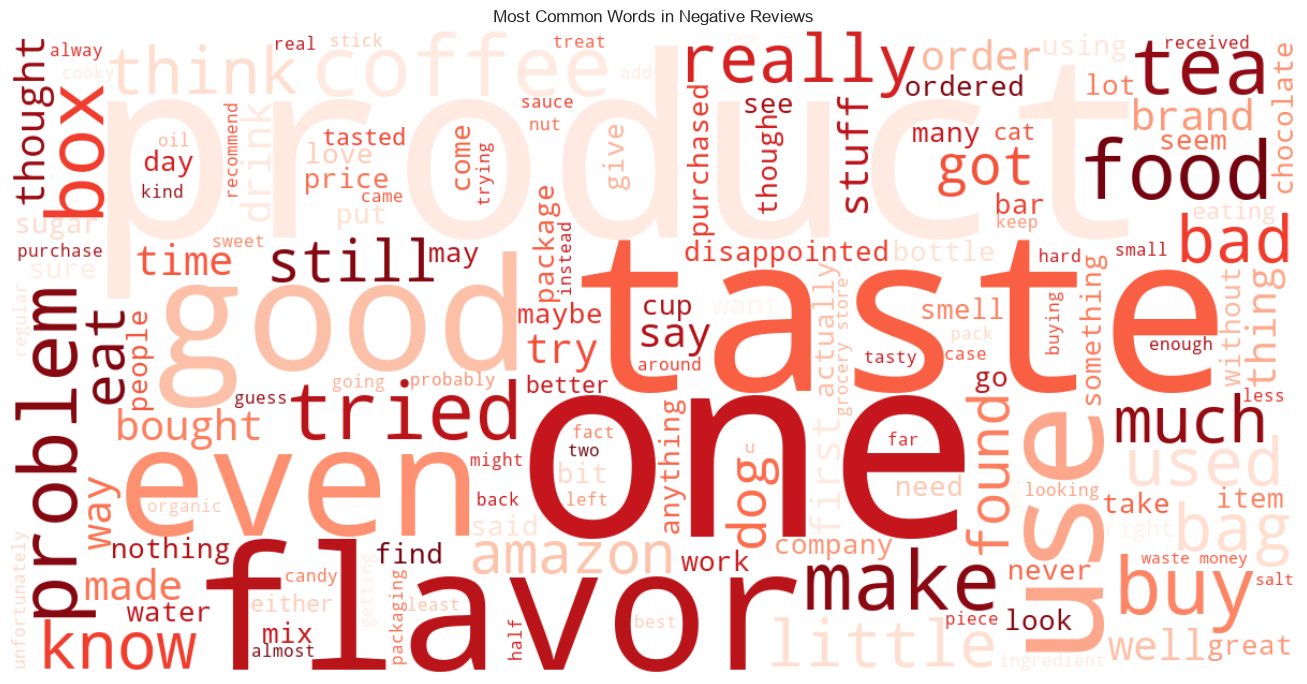

In [20]:
negative_text = " ".join(
    df.loc[df["Sentiment"] == "Negative", "Cleaned_Text"].dropna()
)

if negative_text.strip():

    negative_wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        colormap="Reds",
        max_words=150
    ).generate(negative_text)

    plt.figure(figsize=(14, 7))
    plt.imshow(negative_wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Most Common Words in Negative Reviews")
    plt.tight_layout()

    plt.savefig(
        "visualizations/negative_wordcloud.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("No negative reviews available for word cloud.")

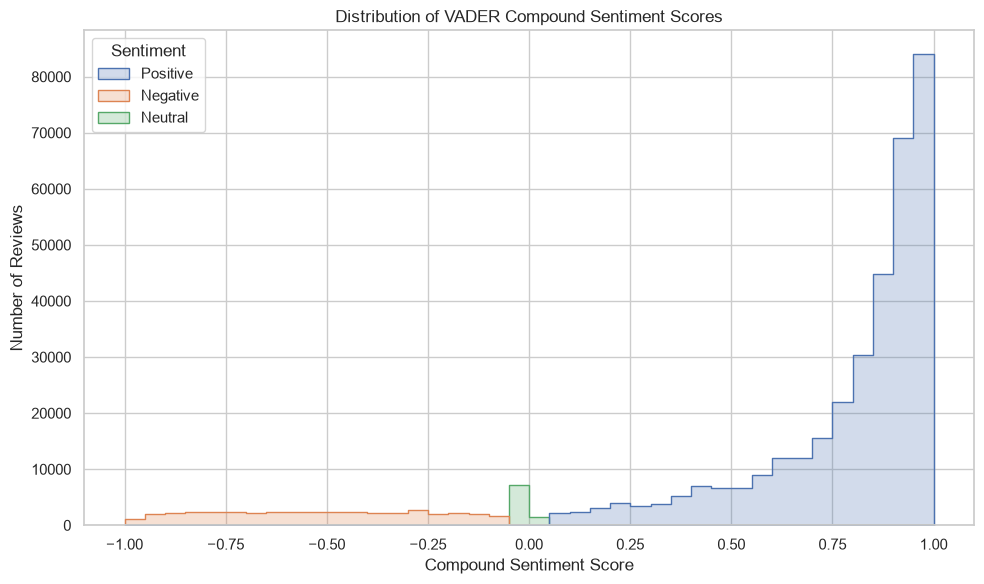

In [21]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Compound_Score",
    hue="Sentiment",
    bins=40,
    element="step",
    stat="count",
    common_norm=False
)

plt.title("Distribution of VADER Compound Sentiment Scores")
plt.xlabel("Compound Sentiment Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(
    "visualizations/compound_score_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
total_reviews = len(df)

sentiment_percent = (
    df["Sentiment"].value_counts(normalize=True) * 100
)

dominant_sentiment = df["Sentiment"].value_counts().idxmax()

positive_percent = sentiment_percent.get("Positive", 0)
negative_percent = sentiment_percent.get("Negative", 0)
neutral_percent = sentiment_percent.get("Neutral", 0)

average_review_length = df["Review_Length"].mean()

print("========== KEY FINDINGS ==========")

print(f"Total reviews analyzed: {total_reviews:,}")

print(
    f"Positive reviews: {positive_percent:.2f}%"
)

print(
    f"Negative reviews: {negative_percent:.2f}%"
)

print(
    f"Neutral reviews: {neutral_percent:.2f}%"
)

print(
    f"Dominant sentiment: {dominant_sentiment}"
)

print(
    f"Average review length: {average_review_length:.2f} words"
)

print("\nTop 5 frequent words:")

for word, frequency in word_counts.most_common(5):
    print(f"{word}: {frequency}")

========== KEY FINDINGS ==========
Total reviews analyzed: 393,579
Positive reviews: 87.22%
Negative reviews: 10.55%
Neutral reviews: 2.22%
Dominant sentiment: Positive
Average review length: 79.75 words

Top 5 frequent words:
not: 239051
like: 180401
taste: 152898
good: 140149
product: 132096


In [23]:
OUTPUT_PATH = "data/reviews_cleaned.csv"

df.to_csv(
    OUTPUT_PATH,
    index=False
)

print("Analyzed dataset saved to:", OUTPUT_PATH)
print("Final dataset shape:", df.shape)

Analyzed dataset saved to: data/reviews_cleaned.csv
Final dataset shape: (393579, 18)


In [24]:
sentiment_summary.to_csv(
    "data/sentiment_summary.csv"
)

print("Sentiment summary exported successfully.")

Sentiment summary exported successfully.


In [26]:
df = df.sample(
    n=min(50000, len(df)),
    random_state=42
).reset_index(drop=True)

In [1]:
# ==========================================
# USER INPUT: CUSTOMER REVIEW SENTIMENT TEST
# ==========================================

print("CUSTOMER REVIEW SENTIMENT ANALYZER")
print("-" * 40)

user_review = input("Enter a customer review: ").strip()

if not user_review:
    print("Please enter a valid review.")
else:
    # Analyze sentiment using VADER
    user_scores = sia.polarity_scores(user_review)

    compound_score = user_scores["compound"]

    # Classify sentiment
    if compound_score >= 0.05:
        predicted_sentiment = "Positive"
    elif compound_score <= -0.05:
        predicted_sentiment = "Negative"
    else:
        predicted_sentiment = "Neutral"

    # Display result
    print("\n========== SENTIMENT RESULT ==========")
    print("Review:", user_review)
    print("Predicted Sentiment:", predicted_sentiment)
    print(f"Compound Score: {compound_score:.4f}")

    print("\nDetailed Scores:")
    print(f"Positive Score: {user_scores['pos']:.4f}")
    print(f"Neutral Score:  {user_scores['neu']:.4f}")
    print(f"Negative Score: {user_scores['neg']:.4f}")

CUSTOMER REVIEW SENTIMENT ANALYZER
----------------------------------------


Enter a customer review:  the product for recived safely


NameError: name 'sia' is not defined